# MNIST GAN 统一调试与检查

本项目唯一的调试 notebook，后续数据、模型、训练和评价相关的调试内容均继续维护在这里。实现代码复用 Python 模块，各部分功能与 GAN 原理见 [代码结构说明](代码结构说明.md)，实验配置见 [实验方案](实验方案.md)。

**请选择已安装项目依赖的 Python 内核，重启内核后从上到下运行。** Python 需为 3.10 或更高版本，环境名称不限；默认优先 CUDA，不可用时使用 CPU。当前覆盖：数据加载 → 灰度与归一化 → 调试子集 → 批次与随机顺序 → G/D 结构 → BatchNorm 消融 → 初始输出 → 损失与梯度。

第 1–10 节检查数据、结构和梯度；第 11–13 节接入 E0；第 14–17 节按顺序运行或读取 E1–E3，并统一生成评价样本、测量推理时间和展示对比。E0 使用 6,000 张图训练 2 epochs，不计入正式比较；E1–E3 各使用全部 60,000 张图训练 20 epochs。

In [1]:
import sys
import os
from pathlib import Path

# Windows 内核直接启动 Python 时，补充当前 Conda 环境的 cuDNN DLL 路径。
if sys.platform == 'win32' and (Path(sys.prefix) / 'Library' / 'bin').is_dir():
    dll_dir = str(Path(sys.prefix) / 'Library' / 'bin')
    path_entries = [entry for entry in os.environ.get('PATH', '').split(os.pathsep) if entry != dll_dir]
    os.environ['PATH'] = os.pathsep.join([dll_dir, *path_entries])

import subprocess
import torch
from torch import nn
import torchvision
import matplotlib.pyplot as plt
from torchvision.datasets import MNIST
from torchvision.utils import make_grid
from mnist_data import DEFAULT_DATA_DIR, PROJECT_DIR, load_train_images, make_train_loader
from models import Generator, Discriminator

%matplotlib inline
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Python:', sys.executable)
print('PyTorch:', torch.__version__)
print('torchvision:', torchvision.__version__)
print('项目目录:', PROJECT_DIR)
print('Device:', device)
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(device))

Python: E:\Anaconda\envs\cs5495\python.exe
PyTorch: 2.9.1+cu128
torchvision: 0.24.1+cu128
项目目录: C:\Users\lenovo\Desktop\Homework\CS5494\teamproj
Device: cpu


## 1. 读取已准备的数据

通常直接读取现有 `.pt` 文件；只有处理结果缺失时，才调用数据准备脚本。子进程使用 `sys.executable`，即当前 notebook 内核的 Python。原始训练集仅用于对照预处理和统计标签，标签不进入 GAN 的训练批次。

In [2]:
data_dir = DEFAULT_DATA_DIR
processed_dir = data_dir / 'processed'
if not all((processed_dir / name).exists() for name in ['train_images.pt', 'debug_indices.pt']):
    subprocess.run(
        [sys.executable, '-u', str(PROJECT_DIR / 'prepare_data.py')],
        cwd=PROJECT_DIR, check=True,
    )

images = load_train_images(data_dir)
raw = MNIST(root=str(data_dir), train=True, download=False)
debug_indices = torch.load(processed_dir / 'debug_indices.pt', weights_only=True, map_location='cpu')
print('完整训练张量:', tuple(images.shape), images.dtype)
print('像素范围:', (images.min().item(), images.max().item()))
print('固定调试子集:', len(debug_indices), '张')

完整训练张量: (60000, 1, 28, 28) torch.float32
像素范围: (-1.0, 1.0)
固定调试子集: 6000 张


## 2. 检查灰度和归一化

处理公式为 `x = uint8 / 255`、`x_gan = 2*x - 1`，保留 `1×28×28`。下面对照前 64 张原始图像检查公式，并展示同一张图在三种数值范围中的表示。三幅图的视觉外观应一致；色条显示数值范围的变化。

通过：形状、dtype、像素范围、前 64 张归一化公式。首张图包含 85 个灰度值。


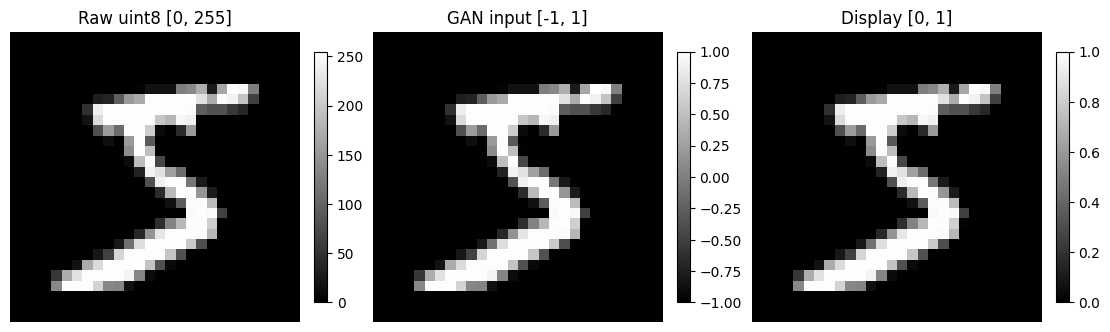

In [3]:
assert images.shape == (60_000, 1, 28, 28)
assert images.dtype == torch.float32
assert (images.min().item(), images.max().item()) == (-1.0, 1.0)
expected = raw.data[:64, None].float().div(255).mul(2).sub(1)
torch.testing.assert_close(images[:64], expected, rtol=0, atol=0)
gray_levels = raw.data[0].unique().numel()
assert gray_levels > 2
print(f'通过：形状、dtype、像素范围、前 64 张归一化公式。首张图包含 {gray_levels} 个灰度值。')

fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), layout='constrained')
panels = [
    (raw.data[0], 0, 255, 'Raw uint8 [0, 255]'),
    (images[0, 0], -1, 1, 'GAN input [-1, 1]'),
    ((images[0, 0] + 1) / 2, 0, 1, 'Display [0, 1]'),
]
for ax, (pixels, low, high, title) in zip(axes, panels):
    im = ax.imshow(pixels.numpy(), cmap='gray', vmin=low, vmax=high, interpolation='nearest')
    ax.set_title(title)
    ax.axis('off')
    fig.colorbar(im, ax=ax, shrink=0.75)
plt.show()

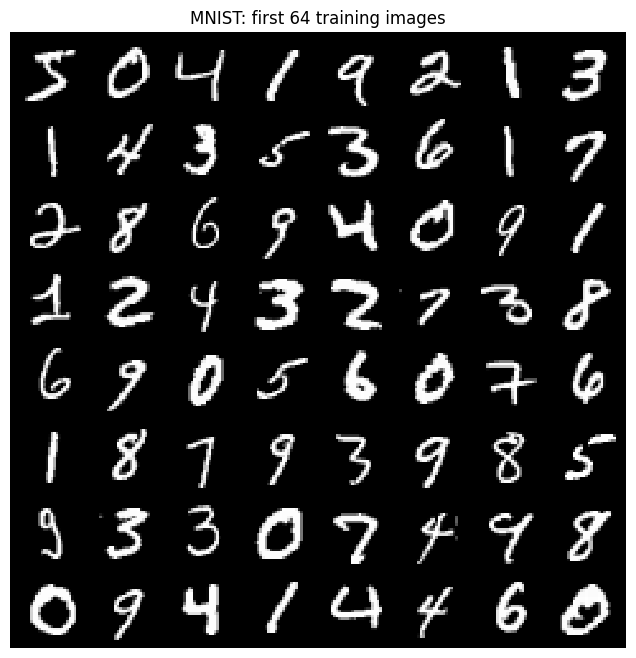

In [4]:
# 固定展示原始顺序前 64 张，不筛选样本；展示时还原到 [0, 1]。
grid = make_grid((images[:64] + 1) / 2, nrow=8, padding=2)
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(grid.permute(1, 2, 0).numpy(), vmin=0, vmax=1, interpolation='nearest')
ax.set_title('MNIST: first 64 training images')
ax.axis('off')
plt.show()

## 3. 固定调试子集与类别分布

调试集由独立生成器以种子 42 无放回抽取 6,000 张，供 E0 使用；正式实验仍使用全部 60,000 张。核对保存的索引后，分别显示两组的类别分布。这里的标签仅用于说明数据分布。

通过：固定种子 42 的 6,000 个索引可复现，且没有重复。
数字  完整训练集  调试子集
 0      5923       595
 1      6742       643
 2      5958       601
 3      6131       625
 4      5842       565
 5      5421       553
 6      5918       585
 7      6265       627
 8      5851       632
 9      5949       574


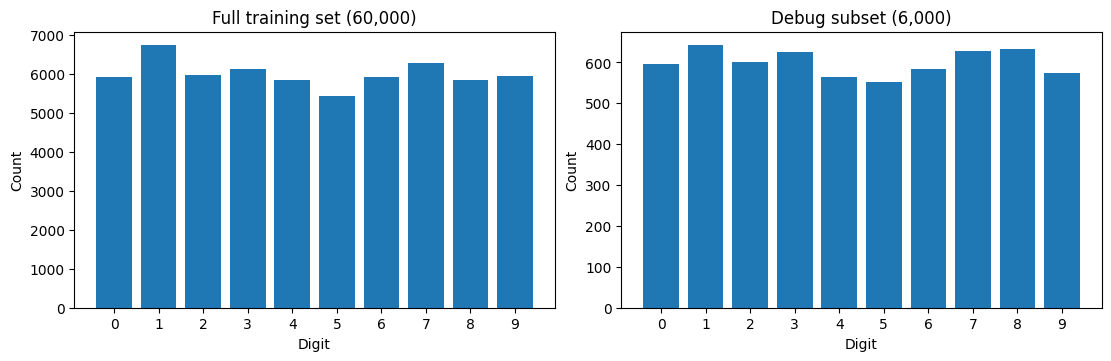

In [5]:
expected_indices = torch.randperm(60_000, generator=torch.Generator().manual_seed(42))[:6_000]
assert torch.equal(debug_indices, expected_indices)
assert debug_indices.unique().numel() == 6_000
full_counts = torch.bincount(raw.targets, minlength=10)
debug_counts = torch.bincount(raw.targets[debug_indices], minlength=10)
print('通过：固定种子 42 的 6,000 个索引可复现，且没有重复。')
print('数字  完整训练集  调试子集')
for digit, full_count, debug_count in zip(range(10), full_counts.tolist(), debug_counts.tolist()):
    print(f'{digit:>2}    {full_count:>6}    {debug_count:>6}')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout='constrained')
for ax, counts, title in zip(axes, [full_counts, debug_counts], ['Full training set (60,000)', 'Debug subset (6,000)']):
    ax.bar(range(10), counts.numpy())
    ax.set(xticks=range(10), xlabel='Digit', ylabel='Count', title=title)
plt.show()

## 4. 检查训练批次

直接调用后续训练使用的 `make_train_loader`，各遍历一个数据轮次，仅检查数据，不计算模型或梯度。默认 batch size 为 128，批次只包含图像，且不丢弃最后一批。完整集应为 469 批、末批 96 张；调试集应为 47 批、末批 112 张。

In [6]:
formal_loader = make_train_loader(data_dir, seed=42)
debug_loader = make_train_loader(data_dir, debug=True, seed=42)

def inspect_loader(loader, expected_samples, expected_batches, expected_last):
    samples, batches = 0, 0
    for batch in loader:
        assert isinstance(batch, torch.Tensor)
        assert batch.dtype == torch.float32 and batch.shape[1:] == (1, 28, 28)
        if batches == 0:
            first_batch = batch.clone()
        samples += len(batch)
        batches += 1
        last_batch_size = len(batch)
    assert (samples, batches, last_batch_size) == (expected_samples, expected_batches, expected_last)
    print(f'通过：{samples:,} 张，{batches} 批，末批 {last_batch_size} 张；批次仅包含图像。')
    return first_batch

formal_first_batch = inspect_loader(formal_loader, 60_000, 469, 96)
debug_first_batch = inspect_loader(debug_loader, 6_000, 47, 112)

通过：60,000 张，469 批，末批 96 张；批次仅包含图像。
通过：6,000 张，47 批，末批 112 张；批次仅包含图像。


## 5. 检查打乱与复现

跨 epoch 复用同一个 loader 时，随机顺序应继续变化；以相同种子重新创建 loader 时，第一批应一致。数据抽样使用独立随机数流，不消耗后续模型训练使用的全局 PyTorch 随机数状态。

In [7]:
rng_before = torch.random.get_rng_state().clone()
replay_loader = make_train_loader(data_dir, debug=True, seed=42)
replay_first_batch = next(iter(replay_loader))
assert torch.equal(debug_first_batch, replay_first_batch)
assert torch.equal(rng_before, torch.random.get_rng_state())
second_epoch_first_batch = next(iter(debug_loader))
assert not torch.equal(debug_first_batch, second_epoch_first_batch)
print('通过：同种子第一批可复现，下一轮第一批发生变化，未消耗全局 PyTorch 随机数状态。')
del replay_loader, replay_first_batch, second_epoch_first_batch

通过：同种子第一批可复现，下一轮第一批发生变化，未消耗全局 PyTorch 随机数状态。


## 6. 创建模型并查看结构

G 使用 `Linear → ReLU → Reshape → ConvTranspose2d → BatchNorm → ReLU → ConvTranspose2d → Tanh`，输出范围对应数据的 `[-1,1]`。D 使用两层卷积与 LeakyReLU，再展平为一个 logit；配合 `BCEWithLogitsLoss` 使用，不额外添加 Sigmoid。所有可学习层保留 bias，使用 PyTorch 默认初始化。

In [8]:
torch.manual_seed(42)
generator = Generator(latent_dim=100, use_batchnorm=True).to(device)
discriminator = Discriminator().to(device)
criterion = nn.BCEWithLogitsLoss()

print(generator)
print(discriminator)
print('G parameters:', sum(p.numel() for p in generator.parameters()))
print('D parameters:', sum(p.numel() for p in discriminator.parameters()))

Generator(
  (project): Sequential(
    (0): Linear(in_features=100, out_features=6272, bias=True)
    (1): ReLU()
    (2): Unflatten(dim=1, unflattened_size=(128, 7, 7))
  )
  (upsample): Sequential(
    (0): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
  )
  (output): Sequential(
    (0): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): Tanh()
  )
)
Discriminator(
  (features): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): LeakyReLU(negative_slope=0.2)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=6272, out_features=1, bias=True)
  )
)
G parameters: 765761
D parameters: 138561


## 7. 逐层尺寸与不同批大小

先显示各层输出尺寸，再检查批大小 1、128 及两个数据集的末批大小 96、112。这里使用评估模式，避免尺寸检查改变 BatchNorm 的运行统计。

In [9]:
def show_shapes(model, inputs):
    x = inputs
    print('input:', tuple(x.shape))
    for block_name, block in model.named_children():
        for layer_name, layer in block.named_children():
            x = layer(x)
            print(f'{block_name}.{layer_name}: {type(layer).__name__:20} -> {tuple(x.shape)}')
    return x

generator.eval()
discriminator.eval()
noise_rng = torch.Generator().manual_seed(2026)
fixed_noise = torch.randn(64, generator.latent_dim, generator=noise_rng).to(device)
with torch.no_grad():
    print('Generator')
    traced_images = show_shapes(generator, fixed_noise[:2])
    print('\nDiscriminator')
    show_shapes(discriminator, traced_images)
    for batch_size in (1, 128, 96, 112):
        z = torch.randn(batch_size, generator.latent_dim, generator=noise_rng).to(device)
        fake = generator(z)
        logits = discriminator(fake)
        assert fake.shape == (batch_size, 1, 28, 28)
        assert logits.shape == (batch_size, 1)
        assert fake.min() >= -1 and fake.max() <= 1
        print(f'通过：batch={batch_size}，G={tuple(fake.shape)}，D={tuple(logits.shape)}')

Generator
input: (2, 100)
project.0: Linear               -> (2, 6272)
project.1: ReLU                 -> (2, 6272)
project.2: Unflatten            -> (2, 128, 7, 7)
upsample.0: ConvTranspose2d      -> (2, 64, 14, 14)
upsample.1: BatchNorm2d          -> (2, 64, 14, 14)
upsample.2: ReLU                 -> (2, 64, 14, 14)
output.0: ConvTranspose2d      -> (2, 1, 28, 28)
output.1: Tanh                 -> (2, 1, 28, 28)

Discriminator
input: (2, 1, 28, 28)
features.0: Conv2d               -> (2, 64, 14, 14)
features.1: LeakyReLU            -> (2, 64, 14, 14)
features.2: Conv2d               -> (2, 128, 7, 7)
features.3: LeakyReLU            -> (2, 128, 7, 7)
classifier.0: Flatten              -> (2, 6272)
classifier.1: Linear               -> (2, 1)


通过：batch=1，G=(1, 1, 28, 28)，D=(1, 1)
通过：batch=128，G=(128, 1, 28, 28)，D=(128, 1)


通过：batch=96，G=(96, 1, 28, 28)，D=(96, 1)
通过：batch=112，G=(112, 1, 28, 28)，D=(112, 1)


## 8. BatchNorm 消融

`Generator(use_batchnorm=False)` 将唯一的 BatchNorm 替换为无参数的 Identity，其余层保持相同。重新设置相同种子并按相同顺序构造 G、D，核对共同参数的初始值一致；移除 BatchNorm 后应少 128 个可学习参数。

In [10]:
torch.manual_seed(42)
generator_no_bn = Generator(use_batchnorm=False).to(device)
discriminator_no_bn = Discriminator().to(device)
base_parameters = dict(generator.named_parameters())
for name, parameter in generator_no_bn.named_parameters():
    assert torch.equal(parameter, base_parameters[name])
for base_parameter, ablation_parameter in zip(discriminator.parameters(), discriminator_no_bn.parameters()):
    assert torch.equal(base_parameter, ablation_parameter)
assert sum(isinstance(layer, nn.BatchNorm2d) for layer in generator.modules()) == 1
assert not any(isinstance(layer, nn.BatchNorm2d) for layer in generator_no_bn.modules())
assert not any(isinstance(layer, (nn.BatchNorm2d, nn.Dropout, nn.Sigmoid)) for layer in discriminator.modules())
base_count = sum(p.numel() for p in generator.parameters())
ablation_count = sum(p.numel() for p in generator_no_bn.parameters())
assert base_count - ablation_count == 128
generator_no_bn.eval()
with torch.no_grad():
    assert generator_no_bn(fixed_noise).shape == (64, 1, 28, 28)
print('G with BatchNorm:', base_count)
print('G without BatchNorm:', ablation_count)
print('通过：仅移除 BatchNorm，共同层初始参数一致，D 结构与参数一致。')

G with BatchNorm: 765761
G without BatchNorm: 765633
通过：仅移除 BatchNorm，共同层初始参数一致，D 结构与参数一致。


## 9. 未训练输出预览

使用独立种子 2026 的固定噪声展示 64 张初始输出。显示时由 `[-1,1]` 映射回 `[0,1]`，固定显示范围；此时模型尚未训练，图像不代表数字生成质量。

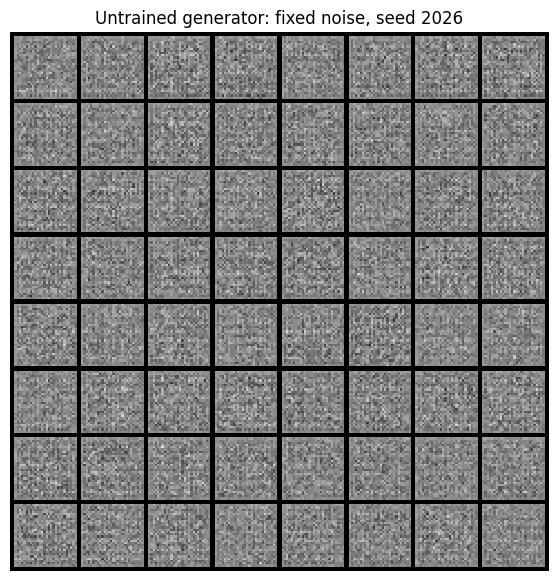

Initial output range: -0.6563453674316406 0.7541177272796631


In [11]:
with torch.no_grad():
    initial_images = generator(fixed_noise).cpu()
grid = make_grid((initial_images + 1) / 2, nrow=8, padding=2)
fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(grid.permute(1, 2, 0).numpy(), vmin=0, vmax=1, interpolation='nearest')
ax.set_title('Untrained generator: fixed noise, seed 2026')
ax.axis('off')
plt.show()
print('Initial output range:', initial_images.min().item(), initial_images.max().item())

## 10. 真实数据、损失与梯度方向

取现有调试集的一批真实图像，在两种 G 配置上各做一次反向传播检查。D 阶段对假图像使用 `detach()`，损失为真实项均值与假图项均值之和，只有 D 获得梯度；G 阶段重新采样噪声并冻结 D 参数，保留经过 D 的计算图，只有 G 获得梯度。

不调用 `optimizer.step()`，不更新模型权重；下方数值只是初始损失检查，不是训练结果。

In [12]:
real_images = next(iter(make_train_loader(debug=True))).to(device)
batch_size = len(real_images)

for use_batchnorm in (True, False):
    # 使用新建的检查模型，保留上面用于结构展示的模型状态。
    torch.manual_seed(42)
    g = Generator(use_batchnorm=use_batchnorm).to(device)
    d = Discriminator().to(device)
    g.train()
    d.train()
    g.zero_grad(set_to_none=True)
    d.zero_grad(set_to_none=True)

    fake_images = g(torch.randn(batch_size, g.latent_dim, device=device))
    real_logits = d(real_images)
    fake_logits = d(fake_images.detach())
    d_loss = criterion(real_logits, torch.ones_like(real_logits)) + criterion(fake_logits, torch.zeros_like(fake_logits))
    d_loss.backward()
    assert torch.isfinite(d_loss)
    assert all(p.grad is None for p in g.parameters())
    assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in d.parameters())
    assert any(p.grad.abs().sum() > 0 for p in d.parameters())

    d.zero_grad(set_to_none=True)
    d.requires_grad_(False)
    try:
        new_fake_images = g(torch.randn(batch_size, g.latent_dim, device=device))
        generator_logits = d(new_fake_images)
        g_loss = criterion(generator_logits, torch.ones_like(generator_logits))
        g_loss.backward()
        assert torch.isfinite(g_loss)
        assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in g.parameters())
        assert any(p.grad.abs().sum() > 0 for p in g.parameters())
        assert all(p.grad is None for p in d.parameters())
    finally:
        d.requires_grad_(True)
    print(f'通过：BatchNorm={use_batchnorm}，D loss={d_loss.item():.6f}，G loss={g_loss.item():.6f}，detach 与冻结 D 的梯度行为正确。')

del g, d, real_logits, fake_logits, generator_logits, d_loss, g_loss, fake_images, new_fake_images

通过：BatchNorm=True，D loss=1.401050，G loss=0.725237，detach 与冻结 D 的梯度行为正确。
通过：BatchNorm=False，D loss=1.417452，G loss=0.705659，detach 与冻结 D 的梯度行为正确。


## 11. E0 配置与训练入口

训练实现复用 `train.py`：固定 6,000 张调试图像，2 epochs，batch size 128，G/D 学习率均为 0.0002，Adam betas=(0.5,0.999)，种子 42。`run_experiment` 会重新创建模型、优化器和 loader，使用独立种子 2026 的 64 个固定展示噪声。

结果保存到 `E0_OUTPUT_DIR`。已有完整结果时下一格直接读取；如需重新训练，将该目录改为一个新的目录。E1–E3 使用后文的独立正式实验入口。

In [13]:
import csv
import json
import math
from dataclasses import asdict
from IPython.display import Image, display
from train import get_experiment_config, run_experiment

E0_OUTPUT_DIR = PROJECT_DIR / 'outputs' / 'E0' / 'seed_42'
e0_config = get_experiment_config('E0', seed=42)
print(json.dumps(asdict(e0_config), indent=2))
print('Results:', E0_OUTPUT_DIR)

{
  "experiment": "E0",
  "seed": 42,
  "debug": true,
  "epochs": 2,
  "batch_size": 128,
  "latent_dim": 100,
  "learning_rate": 0.0002,
  "betas": [
    0.5,
    0.999
  ],
  "weight_decay": 0.0,
  "use_batchnorm": true,
  "sample_seed": 2026,
  "sample_count": 64
}
Results: C:\Users\lenovo\Desktop\Homework\CS5494\teamproj\outputs\E0\seed_42


## 12. 跑通 E0

每批先更新 D，再更新 G。每个 epoch 完成后保存固定噪声生成图、G/D 权重和 Adam 状态，并记录按样本数加权的损失、D 阶段真假概率和耗时。训练计时包含每轮采样和保存，排除数据/模型准备、epoch 0 预览及训练结束后的曲线绘制。

In [14]:
e0_summary_path = E0_OUTPUT_DIR / 'summary.json'
if e0_summary_path.exists():
    e0_summary = json.loads(e0_summary_path.read_text(encoding='utf-8'))
    print('Loaded completed E0 results:', e0_summary_path)
else:
    e0_summary = run_experiment('E0', seed=42, output_dir=E0_OUTPUT_DIR, device=str(device))
print(json.dumps({key: e0_summary[key] for key in [
    'status', 'completed_epochs', 'samples_per_epoch', 'total_g_updates',
    'total_d_updates', 'training_seconds'
]}, indent=2))

Loaded completed E0 results: C:\Users\lenovo\Desktop\Homework\CS5494\teamproj\outputs\E0\seed_42\summary.json
{
  "status": "completed",
  "completed_epochs": 2,
  "samples_per_epoch": 6000,
  "total_g_updates": 94,
  "total_d_updates": 94,
  "training_seconds": 0.645933400010108
}


## 13. E0 结果、权重与采样检查

检查两轮各遍历 6,000 张、47 批，末批 112 张；G/D 应分别完成 94 次 Adam 更新。核对指标为有限值、模型权重确有变化，并重新加载 checkpoint 生成图像。下面展示同一组噪声的 epoch 0/1/2 输出和原始训练曲线。E0 用于验证训练流程，早期模糊图像不能单独判定模式崩溃。

通过：两轮数据遍历、94 次 G/D 更新、有限指标、权重变化与 checkpoint 重载采样。
epoch   G loss   D loss   D(real)  D(fake)   seconds
  1    2.3951   0.4609   0.8476   0.2217    0.38
  2    5.0361   0.0786   0.9816   0.0319    0.27


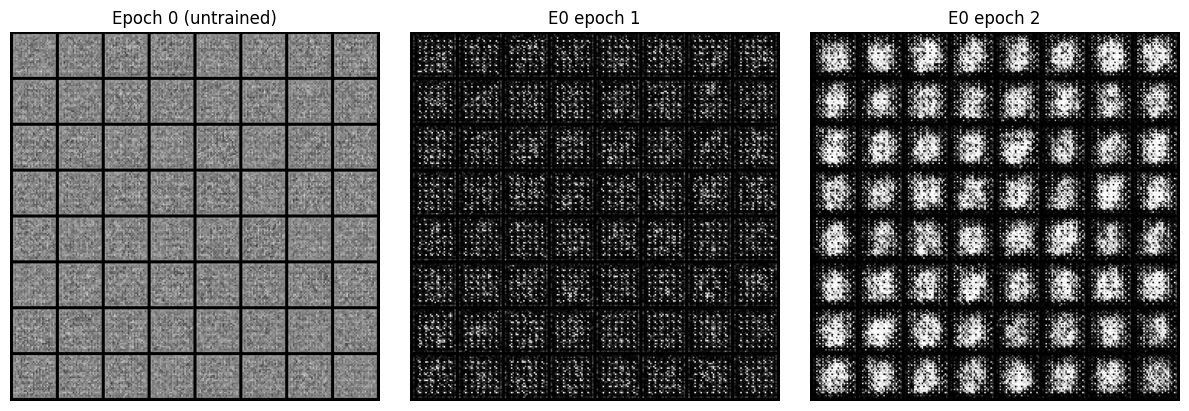

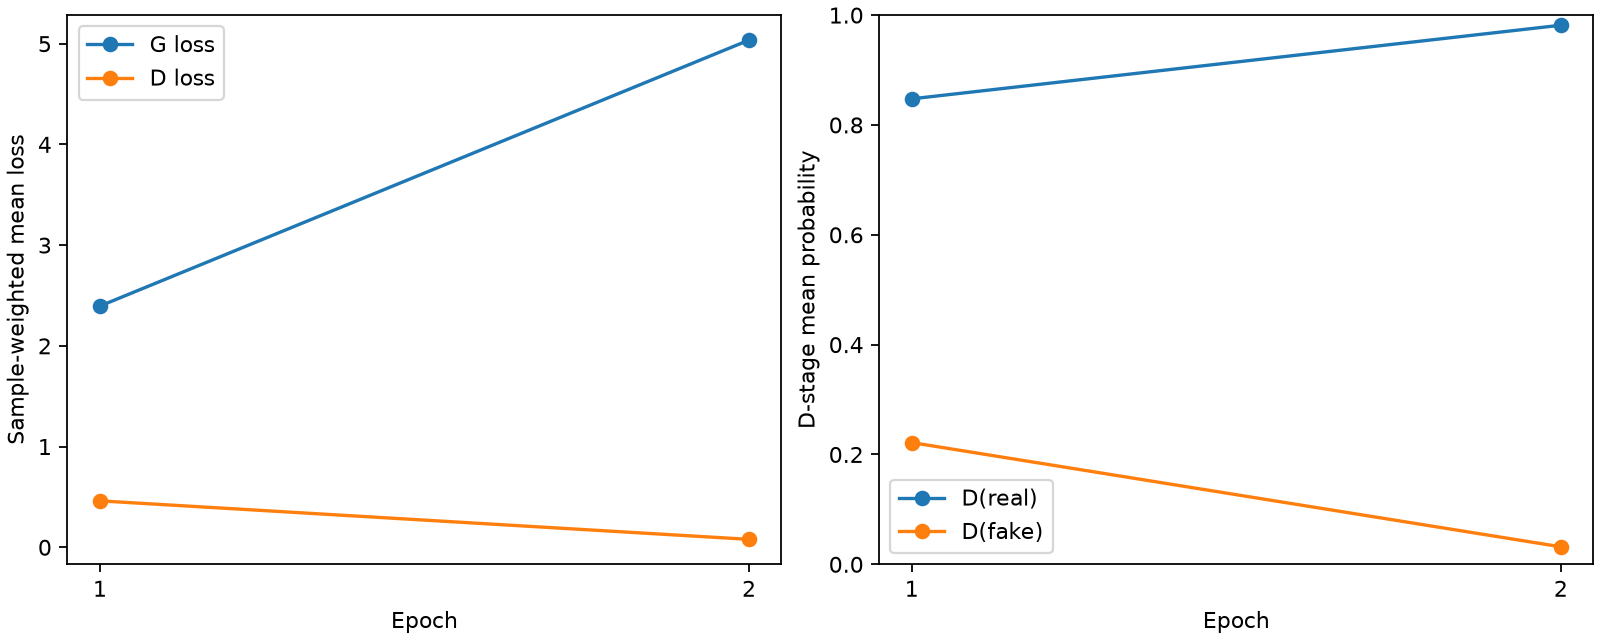

In [15]:
with (E0_OUTPUT_DIR / 'metrics.csv').open(encoding='utf-8', newline='') as file:
    e0_history = list(csv.DictReader(file))
assert e0_summary['status'] == 'completed' and len(e0_history) == 2
assert e0_summary['total_g_updates'] == e0_summary['total_d_updates'] == 94
assert e0_summary['is_formal_comparison'] is False
for row in e0_history:
    assert (int(row['samples']), int(row['batches']), int(row['last_batch_size'])) == (6000, 47, 112)
    for key in ['g_loss', 'd_loss', 'd_real_prob', 'd_fake_prob', 'epoch_seconds']:
        assert math.isfinite(float(row[key]))
    assert 0 <= float(row['d_real_prob']) <= 1 and 0 <= float(row['d_fake_prob']) <= 1

e0_checkpoint = torch.load(E0_OUTPUT_DIR / e0_summary['final_checkpoint'], map_location='cpu', weights_only=True)
assert e0_checkpoint['epoch'] == 2
for key in ['optimizer_g_state_dict', 'optimizer_d_state_dict']:
    assert all(int(state['step'].item()) == 94 for state in e0_checkpoint[key]['state'].values())
for model, key in [(generator, 'generator_state_dict'), (discriminator, 'discriminator_state_dict')]:
    assert any(not torch.equal(parameter.detach().cpu(), e0_checkpoint[key][name]) for name, parameter in model.named_parameters())
trained_generator = Generator(use_batchnorm=True).to(device)
trained_generator.load_state_dict(e0_checkpoint['generator_state_dict'])
trained_generator.eval()
e0_noise = torch.load(E0_OUTPUT_DIR / 'fixed_noise.pt', map_location='cpu', weights_only=True).to(device)
with torch.no_grad():
    reloaded_images = trained_generator(e0_noise)
assert reloaded_images.shape == (64, 1, 28, 28)
assert torch.isfinite(reloaded_images).all()
assert reloaded_images.min() >= -1 and reloaded_images.max() <= 1
print('通过：两轮数据遍历、94 次 G/D 更新、有限指标、权重变化与 checkpoint 重载采样。')
print('epoch   G loss   D loss   D(real)  D(fake)   seconds')
for row in e0_history:
    print(f"{int(row['epoch']):>3}    {float(row['g_loss']):.4f}   {float(row['d_loss']):.4f}   {float(row['d_real_prob']):.4f}   {float(row['d_fake_prob']):.4f}    {float(row['epoch_seconds']):.2f}")

fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout='constrained')
for epoch, ax in enumerate(axes):
    ax.imshow(plt.imread(E0_OUTPUT_DIR / 'samples' / f'epoch_{epoch:03d}.png'))
    ax.set_title('Epoch 0 (untrained)' if epoch == 0 else f'E0 epoch {epoch}')
    ax.axis('off')
plt.show()
display(Image(filename=str(E0_OUTPUT_DIR / 'training_curves.png')))

### 本次 E0 的观察（2026-11-06）

两轮数据遍历、G/D 各 94 次 Adam 更新和 checkpoint 重载检查均已通过，具体指标见上方实际输出。阶段图仍主要是噪声斑块和模糊笔画，尚未形成清晰数字；D 阶段对真实样本的判真概率升高、对生成样本的判真概率降低，说明这一短程阶段 D 较容易区分真假。

E0 的目标是跑通训练和记录流程。仅凭两轮调试输出，不能判定正式训练效果或模式崩溃；E1 应重新初始化后使用全部 60,000 张训练图观察完整学习过程。

## 14. E1–E3 的单因素配置

三组均使用全部 60,000 张、20 epochs、batch size 128、种子 42 和同一设备。E1 为学习率 0.0002 的基线；E2 仅将 G/D 学习率降至 0.0001；E3 仅移除 G 的 BatchNorm。每组重新初始化模型、Adam 和 loader，不使用 E0 权重。

每轮 469 批、末批 96 张，因此每组 G/D 各更新 9,380 次。结果目录由 `FORMAL_OUTPUTS_DIR` 控制，已完成的实验直接读取，避免重跑覆盖。

In [16]:
from evaluate import evaluate_experiments, refresh_annotations

FORMAL_OUTPUTS_DIR = PROJECT_DIR / 'outputs'
COMPARISON_DIR = FORMAL_OUTPUTS_DIR / 'comparison' / 'seed_42'
formal_configs = {name: get_experiment_config(name, seed=42) for name in ['E1', 'E2', 'E3']}
for name, config in formal_configs.items():
    print(f'{name}: full MNIST, epochs={config.epochs}, lr={config.learning_rate}, BatchNorm={config.use_batchnorm}, seed={config.seed}')

E1: full MNIST, epochs=20, lr=0.0002, BatchNorm=True, seed=42
E2: full MNIST, epochs=20, lr=0.0001, BatchNorm=True, seed=42
E3: full MNIST, epochs=20, lr=0.0002, BatchNorm=False, seed=42


## 15. 按序运行或读取正式训练

顺序执行可避免多组同时争用 GPU。每组都调用 `train.py` 的同一函数；完成后检查全部 20 轮的数量、指标和更新次数，并记录第一个全量 epoch 的实测耗时。

In [17]:
formal_training = {}
for name in formal_configs:
    run_dir = FORMAL_OUTPUTS_DIR / name / 'seed_42'
    summary_path = run_dir / 'summary.json'
    if summary_path.exists():
        summary = json.loads(summary_path.read_text(encoding='utf-8'))
        print('Loaded completed training:', name)
    else:
        summary = run_experiment(name, seed=42, output_dir=run_dir, device=str(device))
    with (run_dir / 'metrics.csv').open(encoding='utf-8', newline='') as file:
        history = list(csv.DictReader(file))
    assert summary['status'] == 'completed' and len(history) == 20
    assert summary['total_g_updates'] == summary['total_d_updates'] == 9380
    for row in history:
        assert (int(row['samples']), int(row['batches']), int(row['last_batch_size'])) == (60000, 469, 96)
        assert all(math.isfinite(float(row[key])) for key in ['g_loss', 'd_loss', 'd_real_prob', 'd_fake_prob', 'epoch_seconds'])
    formal_training[name] = summary
    print(f"{name}: first full epoch={float(history[0]['epoch_seconds']):.2f}s, total={summary['training_seconds']:.2f}s, G/D updates=9380 each")

Loaded completed training: E1
E1: first full epoch=18.14s, total=335.65s, G/D updates=9380 each
Loaded completed training: E2
E2: first full epoch=18.24s, total=102.36s, G/D updates=9380 each
Loaded completed training: E3
E3: first full epoch=2.65s, total=48.32s, G/D updates=9380 each


## 16. 同一组 200 张评价样本与推理计时

统一加载第 20 轮权重，以独立种子 2027 的同一组 200 个噪声生成样本，展示前 64 张，不筛选。推理使用 eval/no_grad，预热 10 次，再测 30 次生成 1,000 张的耗时；输入噪声预先放在设备上，GPU 计时两端同步，排除加载、采样噪声、绘图与保存。

`evaluate.py` 同时核对 checkpoint 中两个 Adam 的 9,380 次更新，保存匿名 A/B/C 标注图和 600 行 `annotations.csv`。标签为 0–9 或 `unreadable`（也接受“无法辨认”）。每组全部 200 张有效标注后才计算可辨认率和类别覆盖；缺失或无效标签会报告位置，不填入估计结果。当前 600 张人工标注已完成并汇总。

已有评价结果时调用 `refresh_annotations` 刷新人工统计，保留原有训练、采样和推理计时。命令行可运行 `evaluate.py --annotations-only`，无需重新测量推理时间。

In [18]:
comparison_summary_path = COMPARISON_DIR / 'summary.json'
if comparison_summary_path.exists():
    comparison_summary = refresh_annotations(outputs_dir=FORMAL_OUTPUTS_DIR, seed=42)
    print('Refreshed human metrics; retained existing inference timings:', comparison_summary_path)
else:
    comparison_summary = evaluate_experiments(outputs_dir=FORMAL_OUTPUTS_DIR, seed=42, device=str(device))
print('experiment    train_s    inference_1000_ms (mean +/- std)    labels    readable    coverage    unreadable')
for name, result in comparison_summary['results'].items():
    timing = result['inference']
    quality = comparison_summary['annotations'][name]
    readable = f"{quality['recognizable_rate']:.1%}" if quality['recognizable_rate'] is not None else quality['status']
    print(f"{name:>4}       {result['training_seconds']:8.2f}       {timing['batch_mean_ms']:.3f} +/- {timing['batch_std_ms']:.3f}          {quality['labeled_count']}/200    {readable}    {quality['class_coverage']}    {quality['unreadable_count']}")
    if quality['status'] != 'completed':
        print('Annotation issues:', quality['issues'])

Refreshed human metrics; retained existing inference timings: C:\Users\lenovo\Desktop\Homework\CS5494\teamproj\outputs\comparison\seed_42\summary.json
experiment    train_s    inference_1000_ms (mean +/- std)    labels    readable    coverage    unreadable
  E1         335.65       6.222 +/- 0.321          200/200    89.5%    10    21
  E2         102.36       5.319 +/- 0.145          200/200    84.0%    10    32
  E3          48.32       4.583 +/- 0.239          200/200    82.0%    10    36


## 17. 正式结果的统一展示

依次展示三个实验第 20 轮的同噪声最终样本、E1 在 1/5/10/15/20 轮对同 4 个噪声的进展、原始损失和概率曲线，以及包含无法辨认类的 11 类人工计数。结合图像和完整曲线讨论质量、重复和后期退化；单种子结果只支持本次运行的描述。

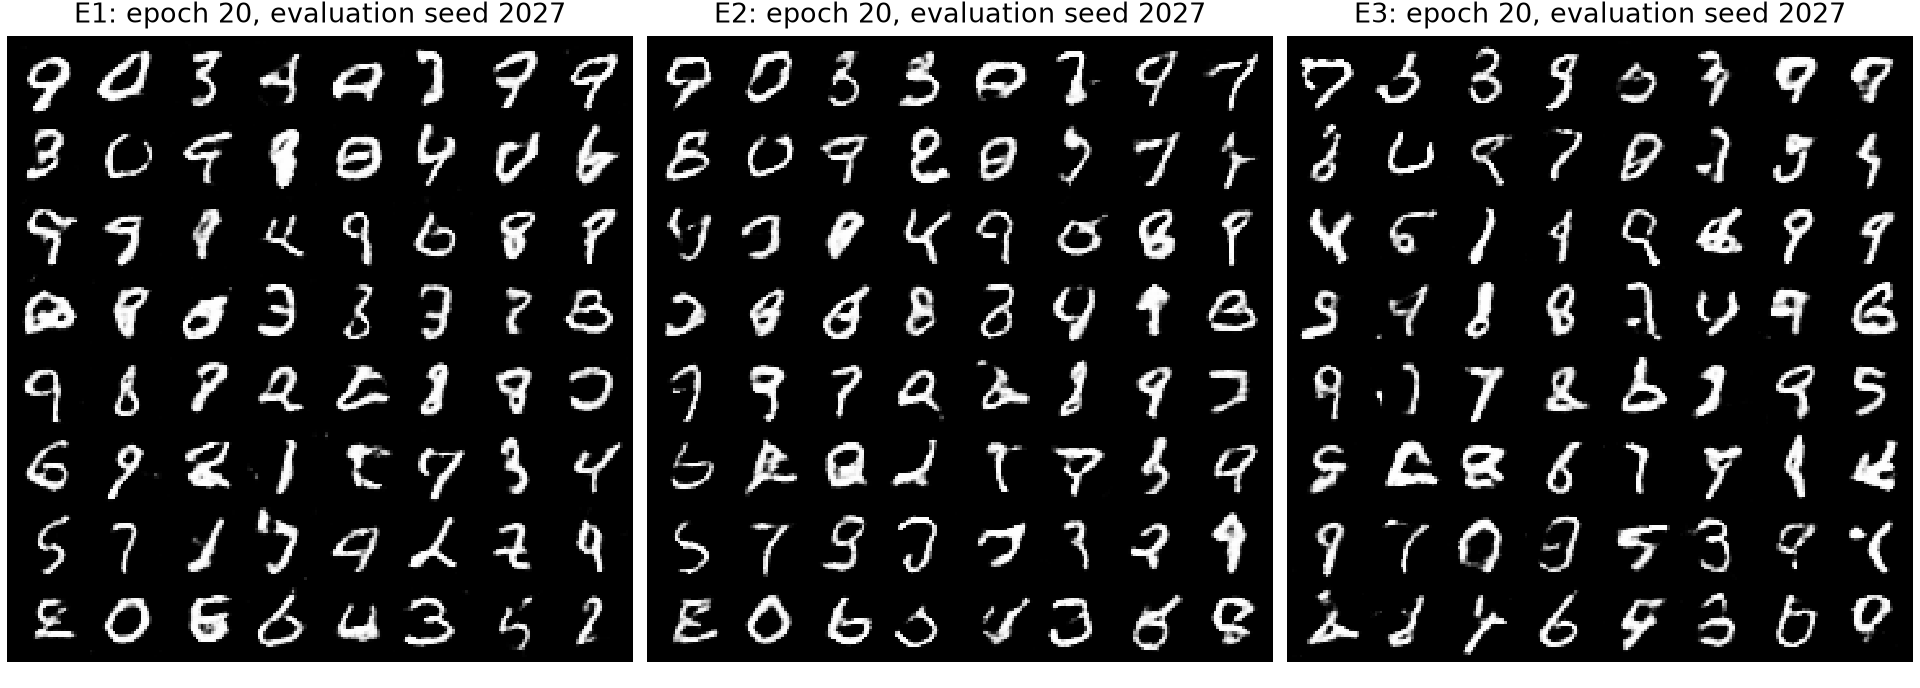

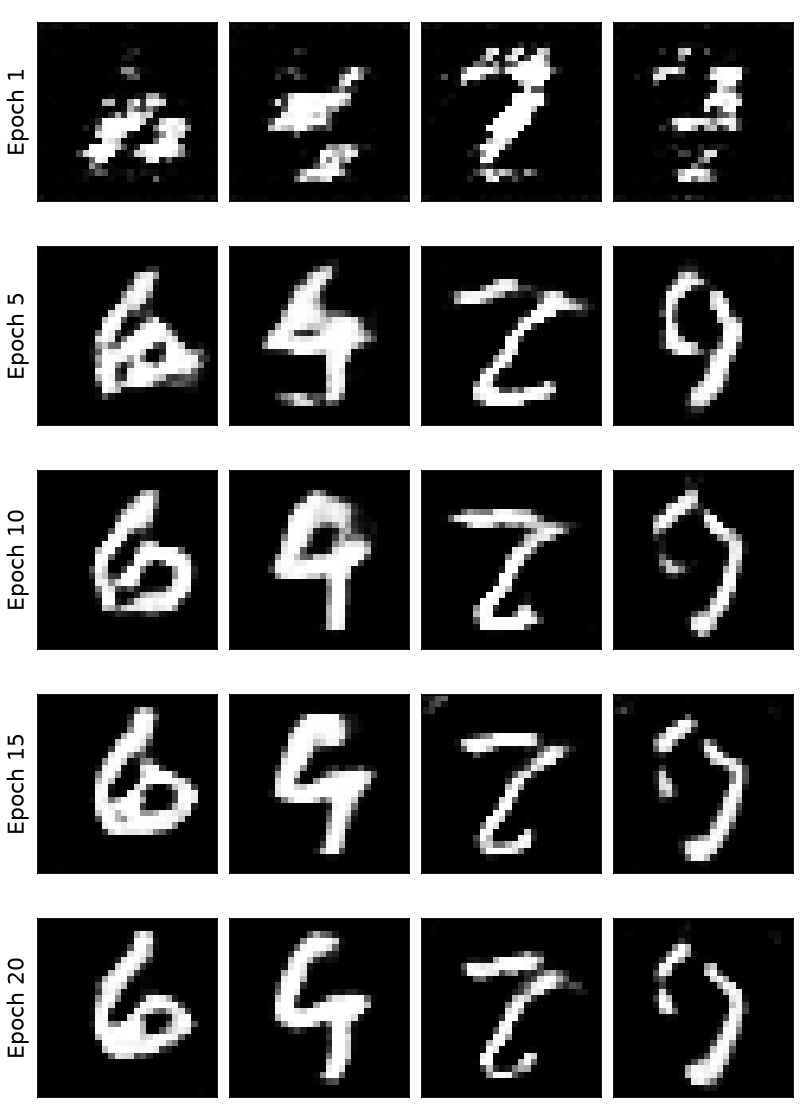

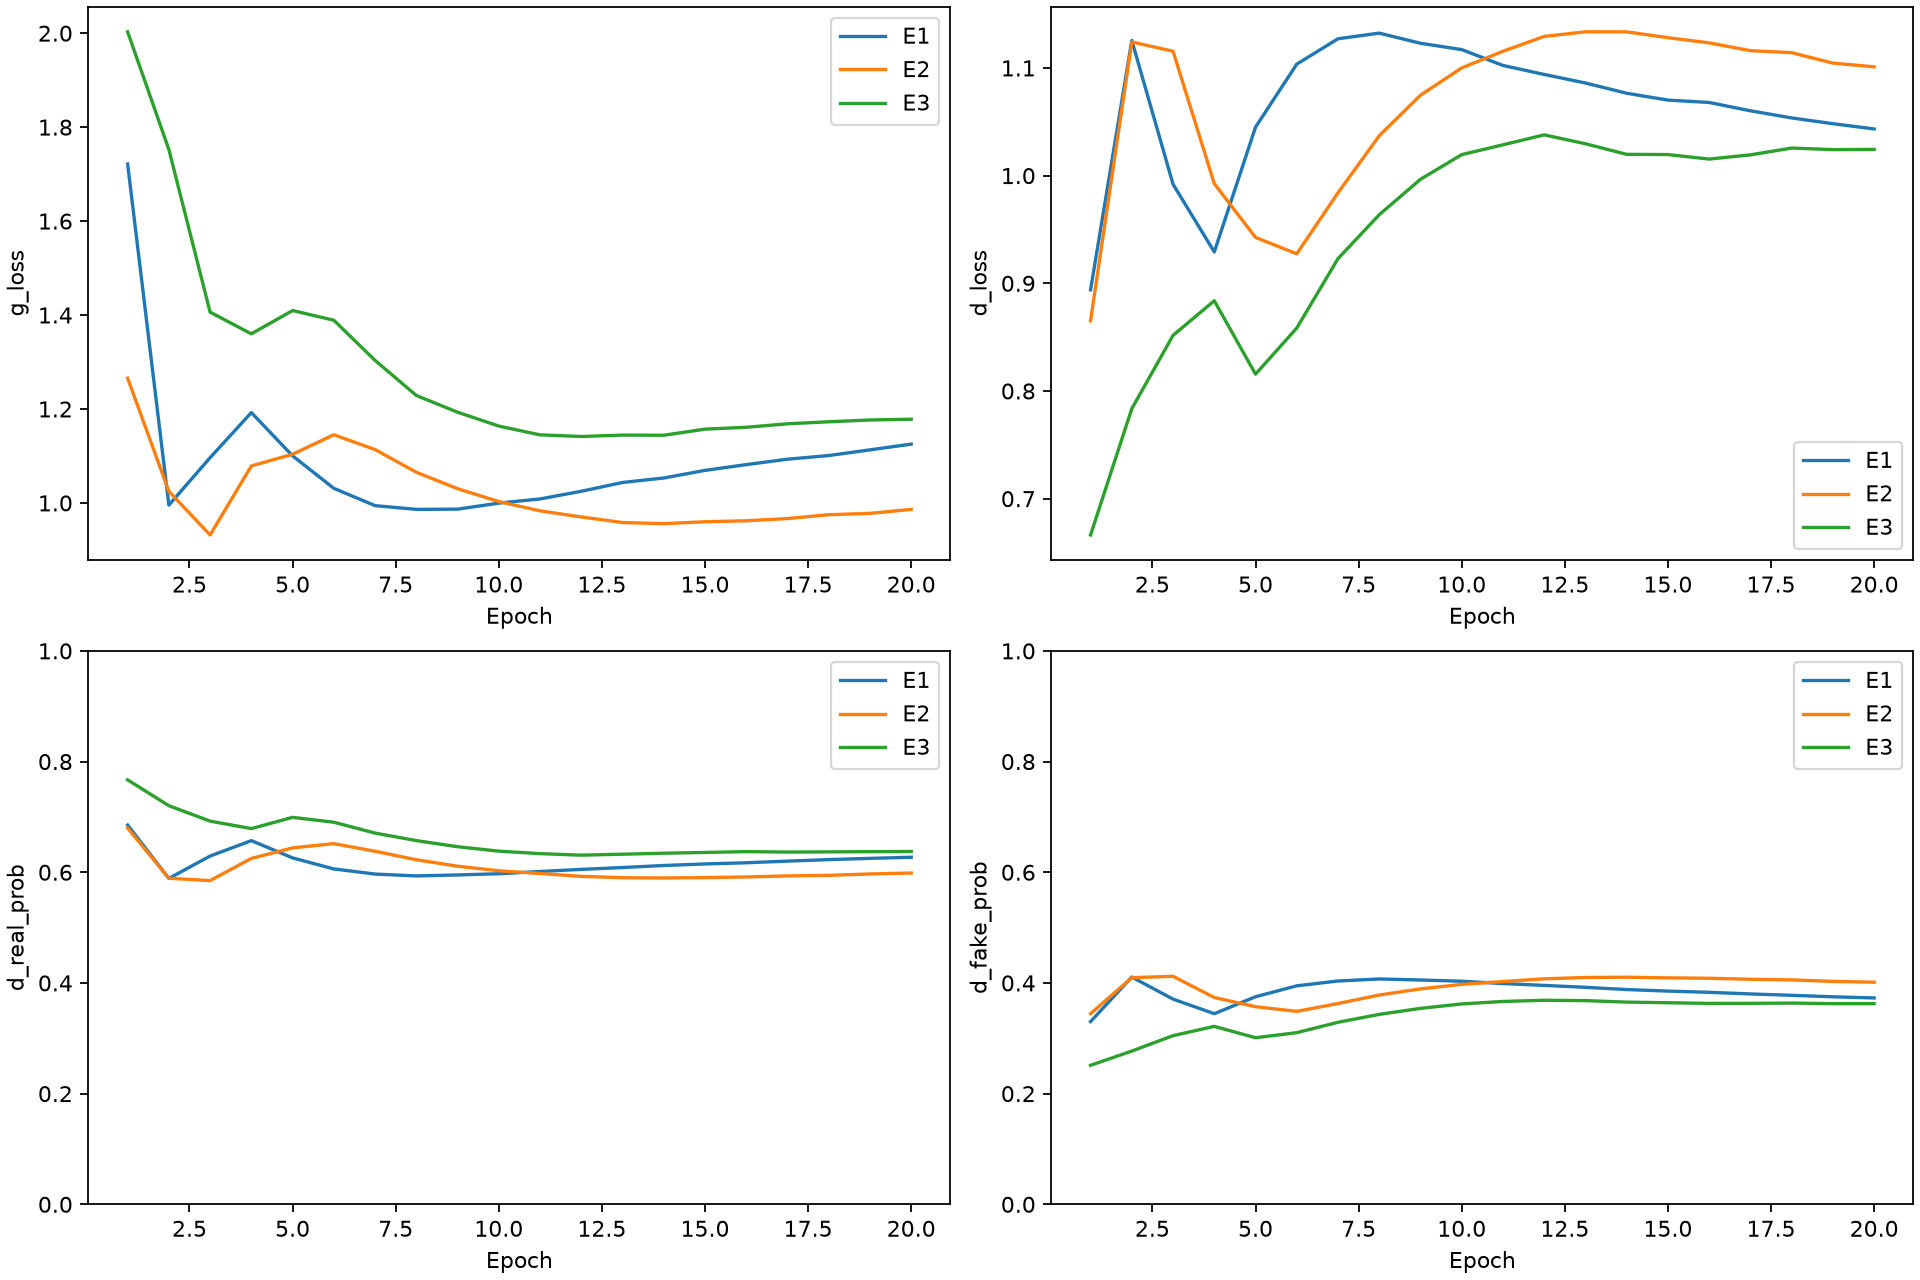

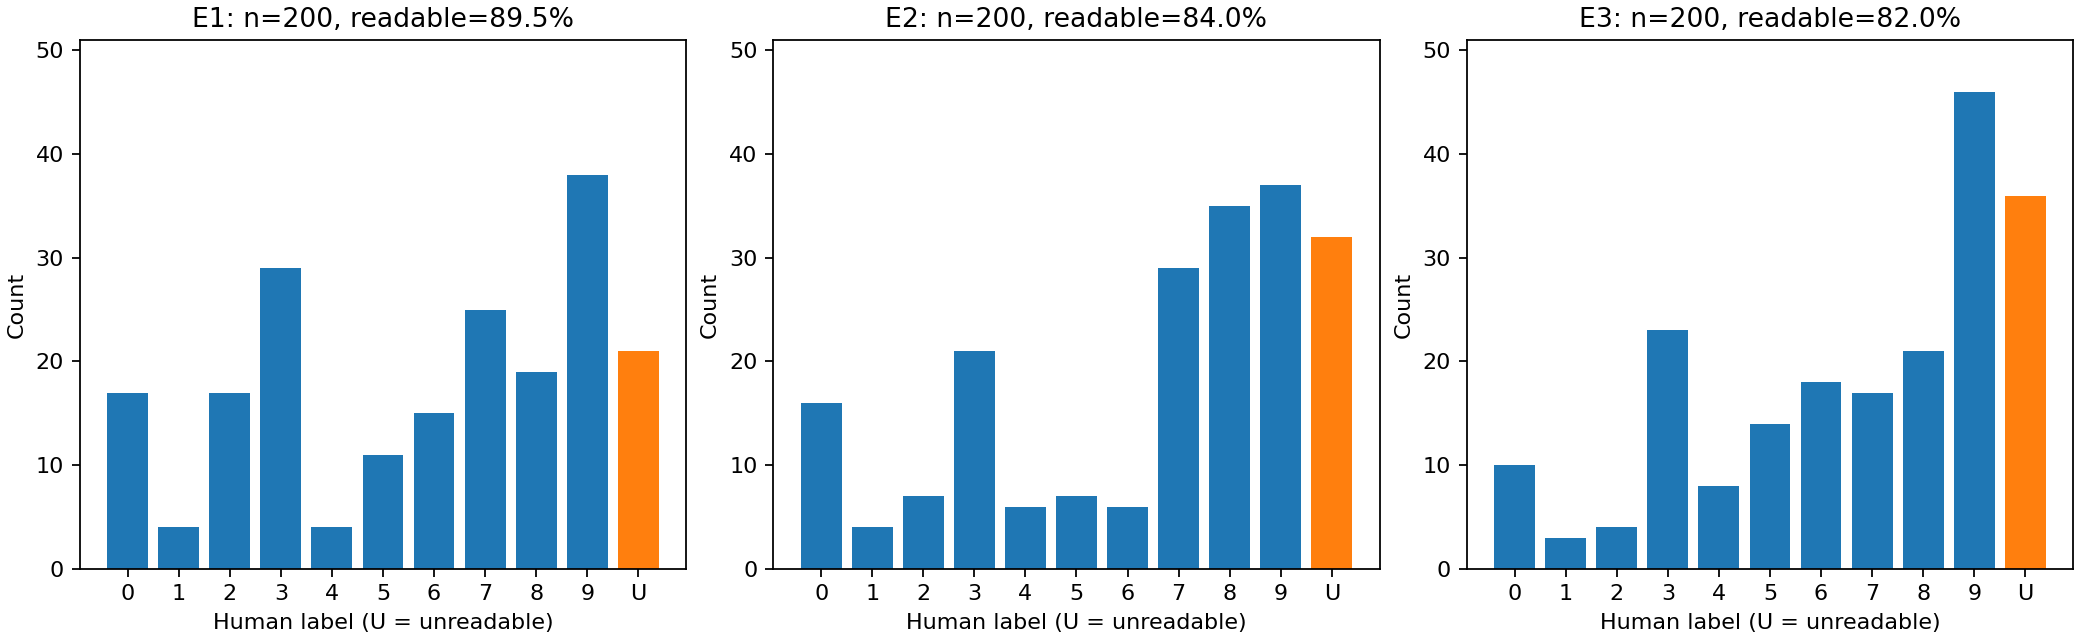

通过：全部正式训练完成、第 20 轮权重可加载、评价噪声一致、计时配置一致。
人工标注状态: {'E3': 'completed', 'E2': 'completed', 'E1': 'completed'}


In [19]:
evaluation_noises = []
for name, result in comparison_summary['results'].items():
    assert result['epoch'] == 20 and result['evaluation_samples'] == 200
    assert result['training_verified']['g_updates'] == result['training_verified']['d_updates'] == 9380
    assert result['inference']['repeats'] == 30 and result['inference']['warmups'] == 10
    evaluation_noises.append(torch.load(FORMAL_OUTPUTS_DIR / name / 'seed_42' / 'evaluation' / 'noise.pt', weights_only=True))
assert all(torch.equal(evaluation_noises[0], noise) for noise in evaluation_noises[1:])
for filename in ['final_samples.png', 'baseline_progress.png', 'training_comparison.png', 'class_distribution.png']:
    display(Image(filename=str(COMPARISON_DIR / filename)))
print('通过：全部正式训练完成、第 20 轮权重可加载、评价噪声一致、计时配置一致。')
print('人工标注状态:', {name: item['status'] for name, item in comparison_summary['annotations'].items()})

### 本次正式实验的观察（2026-11-06）

E1–E3 已完成，均为全量 60,000 张 × 20 epochs、G/D 各 9,380 次更新。三组第 20 轮的同噪声样本均出现多种可辨认数字，仍有部分扭曲或混合笔画；本次最终展示中未见全部输入集中成同一字形的明显现象。E1 的固定输入从前期模糊到形成字形，后期形状相对稳定。单种子与有限展示样本不能用于统计显著性声明或排除类别内部的重复。

训练总耗时为 E1 335.65 s、E2 102.36 s、E3 48.32 s；E2 同一次运行每轮耗时变化约 2.45–18.24 s，具体原因未定位，因此不能将总时间差归因于学习率或 BatchNorm。推理 1,000 张分别为 6.222±0.321、5.319±0.145、4.583±0.239 ms，来自训练结束后的统一 30 次测量。

三组共 600 张人工标注已完成，E1/E2/E3 可辨认率分别为 89.5%/84.0%/82.0%，无法辨认数为 21/32/36，类别覆盖均为 10/10。在本次 20 轮、种子 42 的运行中，E1 比 E2、E3 分别高 5.5、7.5 个百分点；这不代表跨种子或长期训练的普遍结论。

三组数字 1 仅有 3–4 张，数字 9 有 37–46 张，说明类别分布存在偏斜。覆盖全部类别不能排除类别内的重复；还需结合失败与重复样例讨论模式崩溃。不能按 G/D loss 大小给生成质量排名，也不能把不同配置下同一噪声生成了不同数字视为错误。

## 后续维护

E0–E3 训练、记录、重载、同噪声采样和推理计时已接入；后续人工评价及报告相关调试继续维护本 notebook，并同步更新 `代码结构说明.md`。

正式实验开始时，应重新以种子 42 创建模型和 DataLoader；调试期间的遍历会推进 loader 的随机状态。数据层每个 epoch 复用同一个 loader，G/D 的损失计算和更新分别保持独立。当前梯度检查只计算梯度；检查用 G 的 BatchNorm 统计会随训练模式下的前向传播变化，因此正式训练应创建新模型。